In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
maintenance_data = pd.read_csv("ai4i+2020+predictive+maintenance+dataset.zip")
maintenance_data

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0


In [7]:
maintenance_data.shape

(10000, 14)

In [9]:
maintenance_data["Air temperature [C]"] = (maintenance_data["Air temperature [K]"] - 273.15)

maintenance_data["Process temperature [C]"] = (maintenance_data["Process temperature [K]"] - 273.15)

model_data = maintenance_data[
    ["Type",
        "Air temperature [C]",
        "Process temperature [C]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]",
        "Machine failure"]].copy()

model_data = pd.get_dummies(model_data,columns=["Type"],drop_first=True,dtype=int)

X = model_data.drop("Machine failure", axis=1)
y = model_data["Machine failure"]

In [10]:
from sklearn.model_selection import train_test_split

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42, stratify=y)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (8000, 7)
Testing features: (2000, 7)


### Decision Tree Classifier

In [19]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

In [21]:
decision_tree_model = DecisionTreeClassifier(max_depth=5,class_weight="balanced",random_state=42)
decision_tree_model

,criterion,'gini'
,splitter,'best'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,'balanced'


In [24]:
decision_tree_model.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,'balanced'


In [29]:
decision_tree_pred = decision_tree_model.predict(X_test)
print(decision_tree_pred[:20])

[1 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0]


In [30]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, decision_tree_pred))

print("\nClassification Report:")
print(classification_report(y_test, decision_tree_pred))

print("Accuracy:", accuracy_score(y_test, decision_tree_pred))

Confusion Matrix:
[[1799  133]
 [   8   60]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.93      0.96      1932
           1       0.31      0.88      0.46        68

    accuracy                           0.93      2000
   macro avg       0.65      0.91      0.71      2000
weighted avg       0.97      0.93      0.95      2000

Accuracy: 0.9295


In [31]:
from sklearn.ensemble import RandomForestClassifier

In [34]:
random_forest_model = RandomForestClassifier(n_estimators=200,max_depth=10,class_weight="balanced",random_state=42,n_jobs=-1)


In [40]:
random_forest_model.fit(X_train, y_train)

,n_estimators,200
,criterion,'gini'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [41]:
random_forest_pred = random_forest_model.predict(X_test)
random_forest_pred

array([0, 0, 0, ..., 0, 0, 0], shape=(2000,))

In [42]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, random_forest_pred))

print("\nClassification Report:")
print(classification_report(y_test, random_forest_pred))

print("Accuracy:", accuracy_score(y_test, random_forest_pred))

Confusion Matrix:
[[1910   22]
 [  26   42]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.66      0.62      0.64        68

    accuracy                           0.98      2000
   macro avg       0.82      0.80      0.81      2000
weighted avg       0.98      0.98      0.98      2000

Accuracy: 0.976


## Model Performance Comparison

1. Logistic Regression
2. Decision Tree Classifier
3. Random Forest Classifier

All three models were trained using the same training dataset and evaluated using the same test dataset.

The models were compared using Accuracy, Precision, Recall, and F1-score.

**Objective:** To identify the most suitable model for predicting machine failures while reducing false alarms and missed failures.

The comparison results will help us select the best-performing model for further analysis.

In [43]:
model_comparison = pd.DataFrame({"Model": ["Logistic Regression","Decision Tree","Random Forest"],
"Accuracy": [0.8245, 0.9295, 0.9760],"Failure Precision": [0.14, 0.31, 0.66], "Failure Recall": [0.82, 0.88, 0.62],
"Failure F1-score": [0.24, 0.46, 0.64]})

model_comparison

,Model,Accuracy,Failure Precision,Failure Recall,Failure F1-score
0,Logistic Regression,0.8245,0.14,0.82,0.24
1,Decision Tree,0.9295,0.31,0.88,0.46
2,Random Forest,0.9760,0.66,0.62,0.64


## Feature Importance Analysis

After comparing the three classification models, we will analyze the feature importance of the Random Forest model.

The objective is to identify which machine sensor measurements contribute most to predicting machine failures.

This analysis helps us understand the important factors behind machine failure predictions.

### Calculate feature importance

In [44]:
feature_importance = pd.DataFrame({"Feature": X_train.columns,"Importance": random_forest_model.feature_importances_})

feature_importance = feature_importance.sort_values(by="Importance",ascending=False)

feature_importance

,Feature,Importance
3,Torque [Nm],0.314837
2,Rotational speed [rpm],0.300419
4,Tool wear [min],0.208384
0,Air temperature [C],0.096517
1,Process temperature [C],0.063782
5,Type_L,0.009113
6,Type_M,0.006948


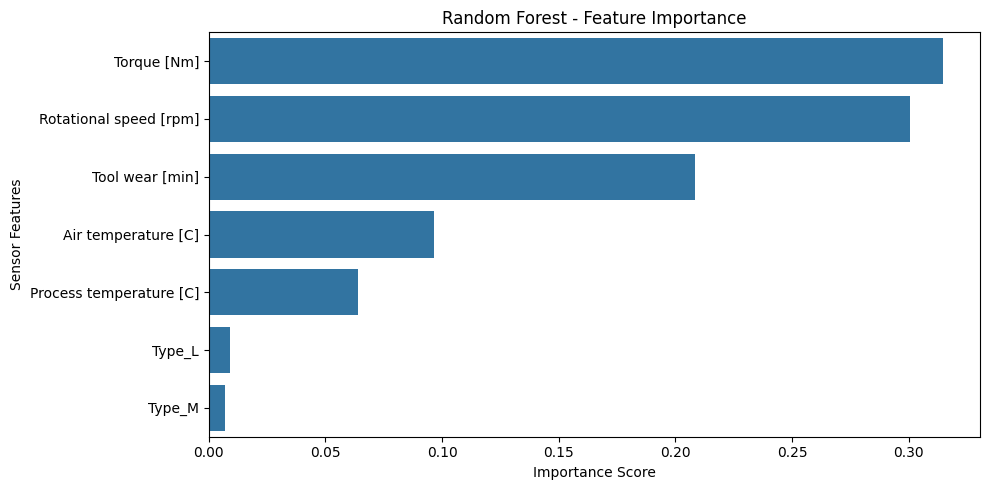

In [45]:
plt.figure(figsize=(10, 5))

sns.barplot(data=feature_importance, x="Importance", y="Feature")
plt.title("Random Forest - Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Sensor Features")

plt.tight_layout()
plt.show()

The Random Forest feature importance analysis identified the most influential input features used by the model.

**Key Observations:**

1. Torque has the highest feature importance.
2. Rotational Speed is the second most important feature.
3. Tool Wear is the third most important feature.
4. Temperature features have moderate importance.
5. Product Type has relatively low importance.

**Conclusion:**

Torque, Rotational Speed, and Tool Wear are the top three predictive features in our Random Forest model.

These results indicate which features the model relies on most for its predictions. However, feature importance does not establish a direct causal relationship with machine failure.

In [49]:
import joblib
from pathlib import Path

model_folder = Path("../models")
model_folder.mkdir(exist_ok=True)

joblib.dump(random_forest_model, model_folder / "random_forest_model.pkl")

joblib.dump(decision_tree_model, model_folder / "decision_tree_model.pkl")

print("Models saved successfully!")

Models saved successfully!


In [50]:
sample_machine = X_test.iloc[[0]]

prediction = random_forest_model.predict(sample_machine)

if prediction[0] == 1:
    print("Machine Failure Predicted!")
else:
    print("No Machine Failure Predicted!")

No Machine Failure Predicted!


In [51]:
actual_value = y_test.iloc[0]
predicted_value = prediction[0]

print("Actual Value:", actual_value)
print("Predicted Value:", predicted_value)

if actual_value == predicted_value:
    print("Prediction is Correct!")
else:
    print("Prediction is Incorrect!")

Actual Value: 0
Predicted Value: 0
Prediction is Correct!


## Project Conclusion

The Predictive Maintenance AI project was developed using the AI4I 2020 dataset.

Three machine learning algorithms were implemented: Logistic Regression, Decision Tree, and Random Forest.

Among these models, Random Forest achieved the highest F1-score of 0.64 and an accuracy of 97.60%.

Feature importance analysis identified Torque, Rotational Speed, and Tool Wear as the top three predictive features.

Finally, the trained model was tested using sensor data and successfully predicted a machine with no failure.

This project helped demonstrate how machine learning can support predictive maintenance by identifying potential machine failures using sensor data.